In [359]:
import pandas as pd
import numpy as np

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, average_precision_score
from sklearn.metrics import roc_curve, precision_recall_curve
from sklearn.metrics import precision_recall_fscore_support

from xgboost import XGBClassifier

import matplotlib.pyplot as plt

from imblearn.over_sampling import SMOTE

In [360]:
# VARIABLES

random_seed = 42

### Load data

In [361]:
url = "https://storage.googleapis.com/download.tensorflow.org/data/creditcard.csv"

df = pd.read_csv(url)

df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [362]:
df["Class"].value_counts(normalize=True)

Class
0    0.998273
1    0.001727
Name: proportion, dtype: float64

### Feature Engineering

In [363]:
x = df.drop("Class", axis=1)
y = df["Class"]

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=random_seed, stratify=y)

x_train["Amount"] = np.log1p(x_train["Amount"])
x_test["Amount"] = np.log1p(x_test["Amount"])

scaler = StandardScaler()
x_train["Amount"] = scaler.fit_transform(x_train[["Amount"]])
x_test["Amount"] = scaler.transform(x_test[["Amount"]])  # Apenas transform no teste!
x_train["Time"] = scaler.fit_transform(x_train[["Time"]])
x_test["Time"] = scaler.transform(x_test[["Time"]])  # Apenas transform no teste!

### Regressão Logistica

In [364]:
def encontrar_melhor_limiar(y_true, y_prob, nome_modelo="Modelo", thresholds=None):
    """
    Testa diferentes limiares de probabilidade e retorna aquele que maximiza o F1-Score da fraude.
    """
    if thresholds is None:
        thresholds = [0.10, 0.20, 0.30, 0.40, 0.50, 0.60, 0.70, 0.80, 0.90]
    print(f"\n{'='*20} OTIMIZAÇÃO DE LIMIAR: {nome_modelo} {'='*20}")
    print(f"{'Limiar':<10} | {'Recall (Fraude)':<18} | {'Precisão (Fraude)':<20} | {'F1-Score'}")
    print("-" * 65)
    best_f1 = 0.0
    best_threshold = 0.50
    for th in thresholds:
        y_pred_th = (y_prob >= th).astype(int)
        p, r, f1, _ = precision_recall_fscore_support(y_true, y_pred_th, average=None, zero_division=0)

        # p[1], r[1], f1[1] referem-se à classe 1 (Fraude)
        print(f"{th:<10.2f} | {r[1]:<18.2%} | {p[1]:<20.2%} | {f1[1]:.4f}")
        if f1[1] > best_f1:
            best_f1 = f1[1]
            best_threshold = th
    print("-" * 65)
    print(f"Melhor Limiar para {nome_modelo}: {best_threshold:.2f} (F1-Score: {best_f1:.4f})\n")
    return best_threshold

def avaliar_modelo(y_true, y_prob, threshold=0.50, nome_modelo="Modelo", plot_graficos=True):
    """
    Exibe o Classification Report, métricas AUC e plota Matriz de Confusão e Curvas.
    """
    # Predição com o limiar especificado
    y_pred = (y_prob >= threshold).astype(int)
    # Métricas numéricas
    roc_auc = roc_auc_score(y_true, y_prob)
    pr_auc = average_precision_score(y_true, y_prob)
    print(f"{'='*25} RELATÓRIO: {nome_modelo} (Limiar {threshold:.2f}) {'='*25}")
    print(classification_report(y_true, y_pred, digits=4))
    print(f"Área sob a Curva ROC (AUC-ROC): {roc_auc:.4f}")
    print(f"Área sob a Curva Precision-Recall (PR-AUC): {pr_auc:.4f}")
    print("-" * 75)
    if plot_graficos:
        fig, axes = plt.subplots(1, 3, figsize=(18, 5))
        # 1. Matriz de Confusão
        ConfusionMatrixDisplay.from_predictions(
            y_true, y_pred,
            display_labels=["Normal", "Fraude"],
            cmap="Blues",
            ax=axes[0]
        )
        axes[0].set_title(f"Matriz de Confusão ({nome_modelo})")
        axes[0].grid(False)
        # 2. Curva ROC
        fpr, tpr, _ = roc_curve(y_true, y_prob)
        axes[1].plot(fpr, tpr, label=f"AUC = {roc_auc:.4f}", color="darkorange")
        axes[1].plot([0, 1], [0, 1], "k--", alpha=0.6)
        axes[1].set_title("Curva ROC")
        axes[1].set_xlabel("Taxa de Falsos Positivos")
        axes[1].set_ylabel("Taxa de Verdadeiros Positivos")
        axes[1].legend()
        # 3. Curva Precision-Recall
        precision, recall, _ = precision_recall_curve(y_true, y_prob)
        axes[2].plot(recall, precision, label=f"PR-AUC = {pr_auc:.4f}", color="forestgreen")
        axes[2].set_title("Curva Precision-Recall")
        axes[2].set_xlabel("Recall")
        axes[2].set_ylabel("Precision")
        axes[2].legend()
        plt.tight_layout()
        plt.show()


==================== OTIMIZAÇÃO DE LIMIAR: Regressão Logística ====================
Limiar     | Recall (Fraude)    | Precisão (Fraude)    | F1-Score
-----------------------------------------------------------------
0.10       | 79.59%             | 72.22%               | 0.7573
0.20       | 72.45%             | 73.96%               | 0.7320
0.30       | 67.35%             | 74.16%               | 0.7059
0.40       | 66.33%             | 79.27%               | 0.7222
0.50       | 62.24%             | 82.43%               | 0.7093
0.60       | 61.22%             | 83.33%               | 0.7059
0.70       | 58.16%             | 83.82%               | 0.6867
0.80       | 54.08%             | 82.81%               | 0.6543
0.90       | 50.00%             | 81.67%               | 0.6203
-----------------------------------------------------------------
Melhor Limiar para Regressão Logística: 0.10 (F1-Score: 0.7573)

========================= RELATÓRIO: Regressão Logística (Limiar 0.10) =====

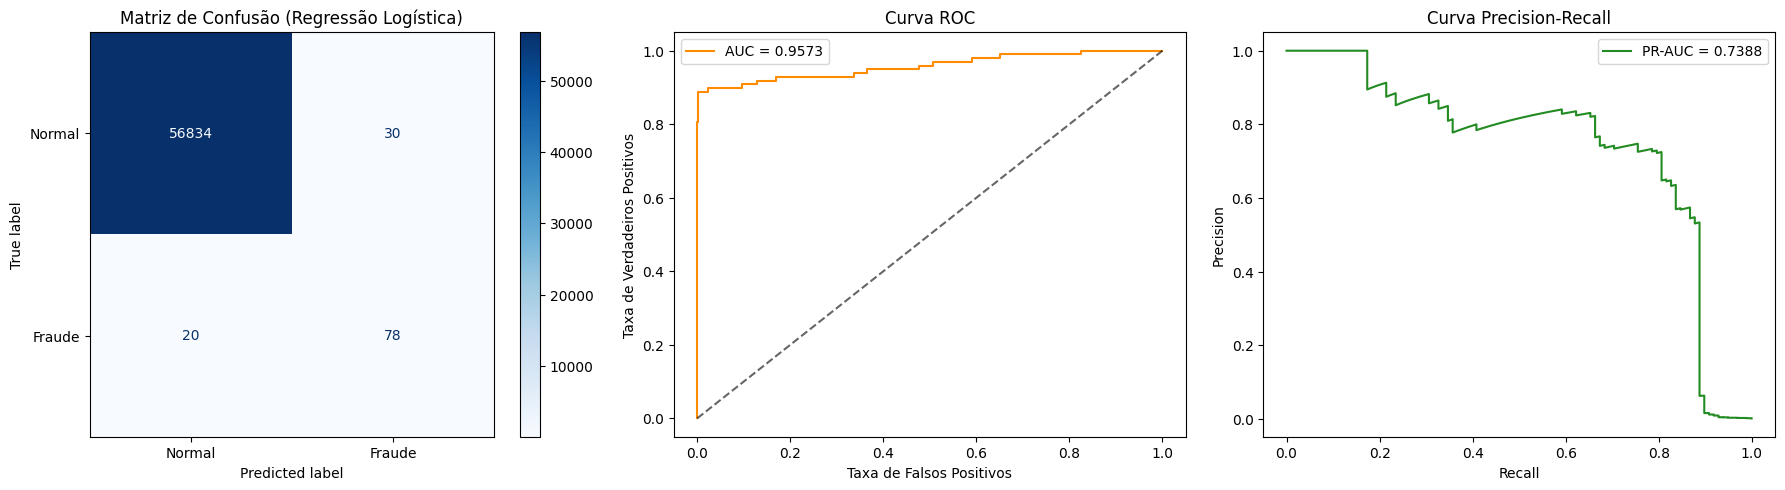

In [365]:
model = LogisticRegression(max_iter=2000, random_state=random_seed)

model.fit(x_train, y_train)

#y_pred = model.predict(x_test)
y_prob = model.predict_proba(x_test)[:, 1]

# Gera a previsão final usando o melhor limiar encontrado:
best_threshold = encontrar_melhor_limiar(y_test, y_prob, nome_modelo="Regressão Logística")
y_pred = (y_prob >= best_threshold).astype(int)
avaliar_modelo(y_test, y_prob,best_threshold,"Regressão Logística")

#### Medindo o modelo

### Data augmentation

In [366]:
# Undersampling (reduz a classe majoritaria)

#fraudes = df[df["Class"] == 1]
#normais = df[df["Class"] == 0].sample(len(fraudes), random_state=random_seed)
#df = pd.concat([fraudes, normais])

# Oversampling (aumenta a classe minoritaria)
# O oversampling aumentou a classe minoritaria porém derrubou a acuracia entao desativei
#smote = SMOTE(random_state=random_seed, sampling_strategy=0.05)
#x_train, y_train = smote.fit_resample(x_train, y_train)

### Random Forest


==================== OTIMIZAÇÃO DE LIMIAR: Random Forest ====================
Limiar     | Recall (Fraude)    | Precisão (Fraude)    | F1-Score
-----------------------------------------------------------------
0.10       | 89.80%             | 12.05%               | 0.2126
0.20       | 89.80%             | 37.77%               | 0.5317
0.30       | 86.73%             | 56.67%               | 0.6855
0.40       | 84.69%             | 73.45%               | 0.7867
0.50       | 82.65%             | 83.51%               | 0.8308
0.60       | 77.55%             | 84.44%               | 0.8085
0.70       | 75.51%             | 85.06%               | 0.8000
0.80       | 71.43%             | 85.37%               | 0.7778
0.90       | 62.24%             | 91.04%               | 0.7394
-----------------------------------------------------------------
Melhor Limiar para Random Forest: 0.50 (F1-Score: 0.8308)

========================= RELATÓRIO: Random Forest (Limiar 0.50) =======================

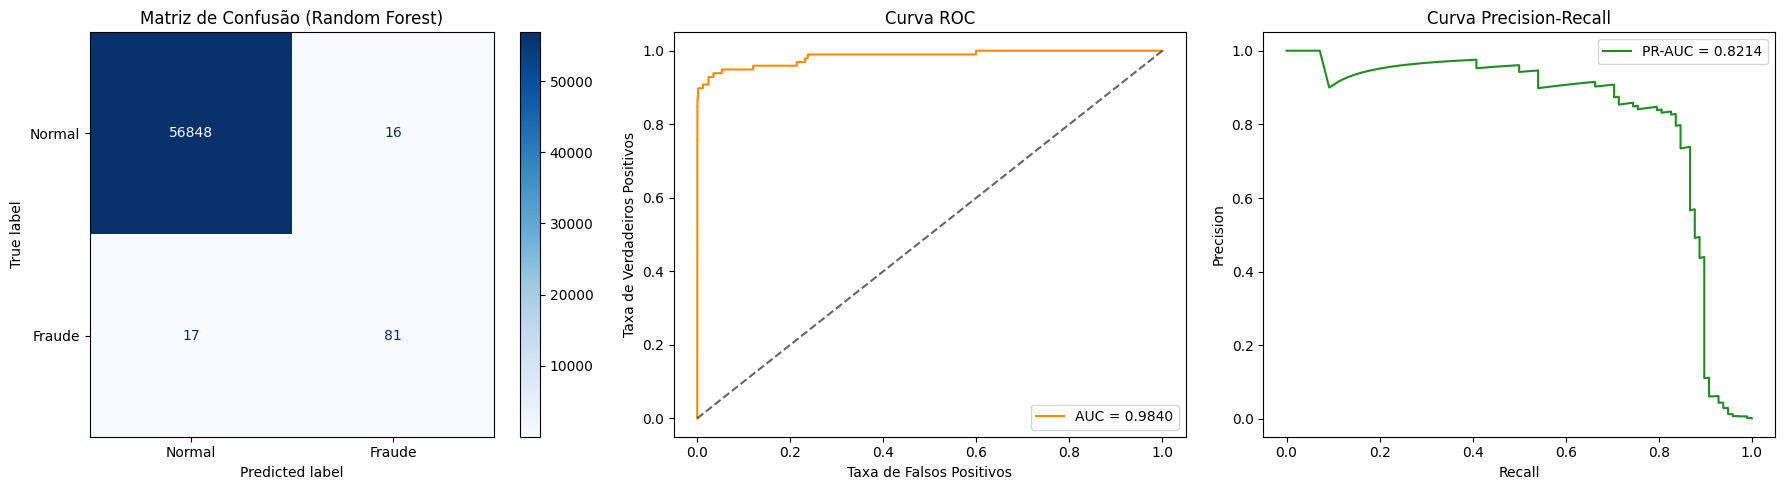

In [367]:

rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=10,
    class_weight="balanced_subsample",
    random_state=random_seed,
    n_jobs=-1
)
rf_model.fit(x_train, y_train)

rf_y_prob = rf_model.predict_proba(x_test)[:, 1]

melhor_limiar_rf = encontrar_melhor_limiar(y_test, rf_y_prob, nome_modelo="Random Forest")

avaliar_modelo(y_test, rf_y_prob, threshold=melhor_limiar_rf, nome_modelo="Random Forest")


==================== OTIMIZAÇÃO DE LIMIAR: XGBoost ====================
Limiar     | Recall (Fraude)    | Precisão (Fraude)    | F1-Score
-----------------------------------------------------------------
0.10       | 85.71%             | 81.55%               | 0.8358
0.20       | 84.69%             | 91.21%               | 0.8783
0.30       | 82.65%             | 91.01%               | 0.8663
0.40       | 82.65%             | 92.05%               | 0.8710
0.50       | 80.61%             | 92.94%               | 0.8634
0.60       | 78.57%             | 95.06%               | 0.8603
0.70       | 74.49%             | 98.65%               | 0.8488
0.80       | 70.41%             | 98.57%               | 0.8214
0.90       | 64.29%             | 100.00%              | 0.7826
-----------------------------------------------------------------
Melhor Limiar para XGBoost: 0.20 (F1-Score: 0.8783)

========================= RELATÓRIO: XGBoost (Limiar 0.20) =========================
              p

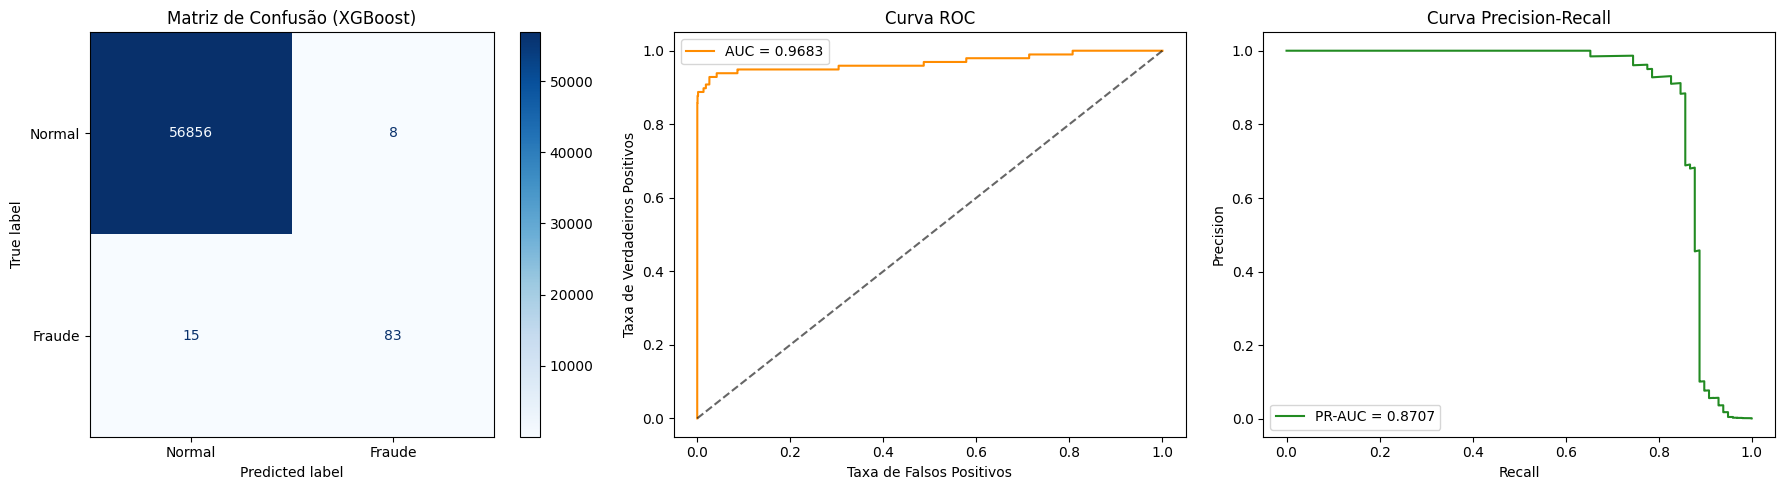

In [384]:
xgb_model = XGBClassifier(
    n_estimators=100,
    max_depth=10,
    learning_rate=0.04,
    random_state=random_seed,
    n_jobs=-1,
    eval_metric="logloss"
)

xgb_model.fit(x_train, y_train)

xgb_y_prob = xgb_model.predict_proba(x_test)[:, 1]

melhor_limiar_xgb = encontrar_melhor_limiar(y_test, xgb_y_prob, nome_modelo="XGBoost")

avaliar_modelo(y_test, xgb_y_prob, threshold=melhor_limiar_xgb, nome_modelo="XGBoost")